     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 59.4 MB/s eta 0:00:00


Saving ddi_edges.csv to ddi_edges.csv
Saving disease1_drug_nodes.csv to disease1_drug_nodes.csv
Saving disease1_edges.csv to disease1_edges.csv
Saving disease1_mechanism_of_action - target.csv to disease1_mechanism_of_action - target.csv
Saving disease1_nodes.csv to disease1_nodes.csv
Saving disease2_drug_nodes.csv to disease2_drug_nodes.csv
Saving disease2_edges.csv to disease2_edges.csv
Saving disease2_mechanism_of_action - target.csv to disease2_mechanism_of_action - target.csv
Saving disease2_nodes.csv to disease2_nodes.csv
Epoch 010 | Loss: 1.0427
Epoch 020 | Loss: 0.8875
Epoch 030 | Loss: 0.7708
Epoch 040 | Loss: 0.6623
Epoch 050 | Loss: 0.5947
Epoch 060 | Loss: 0.5190
Epoch 070 | Loss: 0.4917
Epoch 080 | Loss: 0.4132
Epoch 090 | Loss: 0.4109
Epoch 100 | Loss: 0.4037
Epoch 110 | Loss: 0.3398
Epoch 120 | Loss: 0.3213
Epoch 130 | Loss: 0.3037
Epoch 140 | Loss: 0.2847
Epoch 150 | Loss: 0.2886
Epoch 160 | Loss: 0.2536
Epoch 170 | Loss: 0.2523
Epoch 180 | Loss: 0.2405
Epoch 190 | Loss

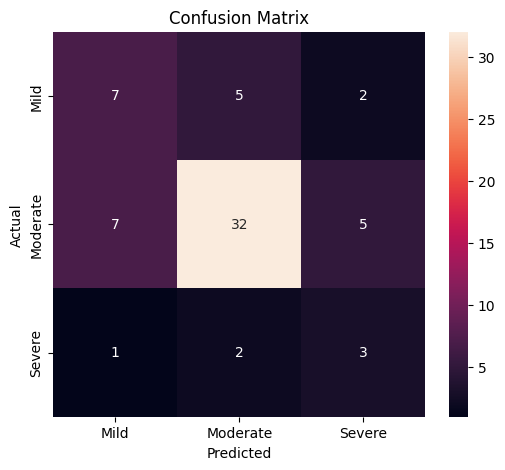

Total cross-disease pairs: 455
Self-interactions excluded.


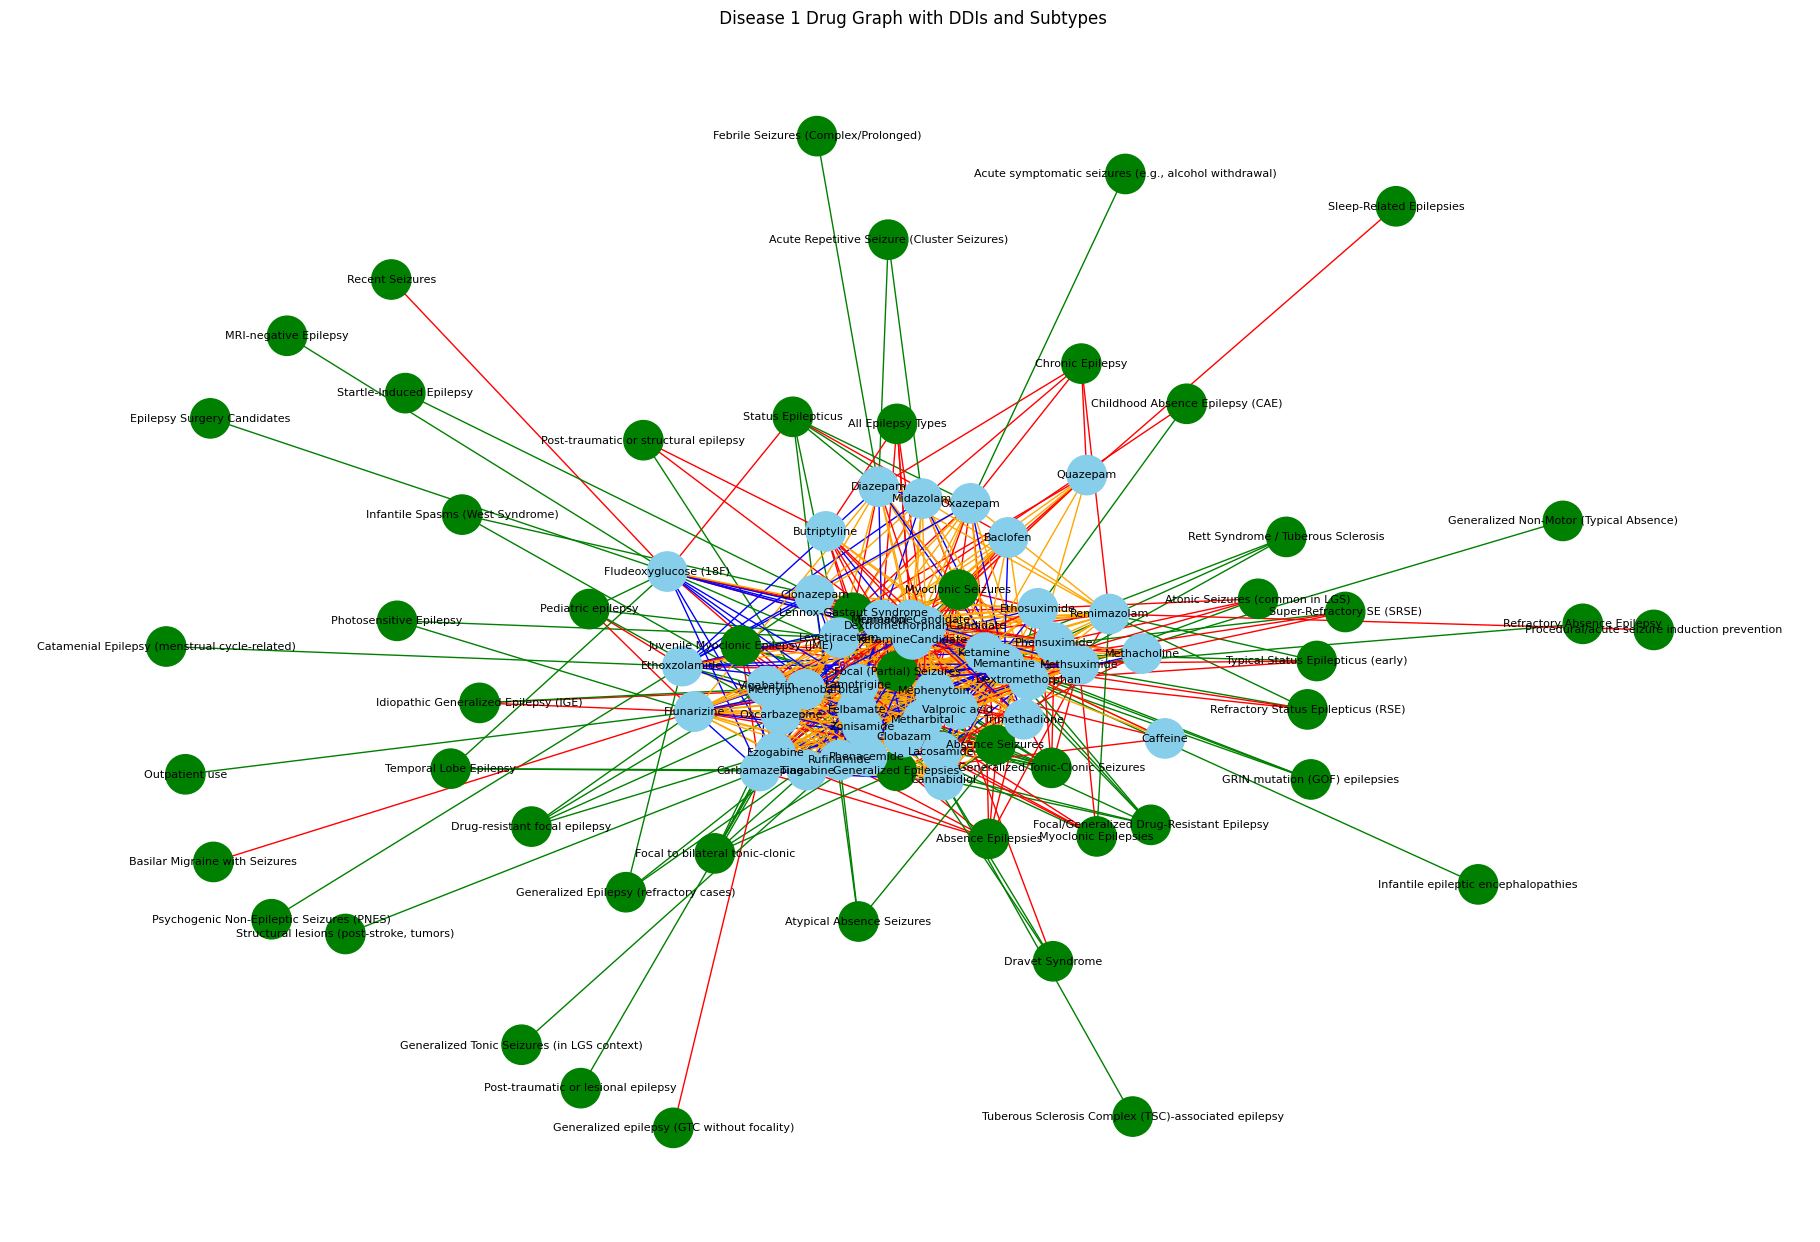

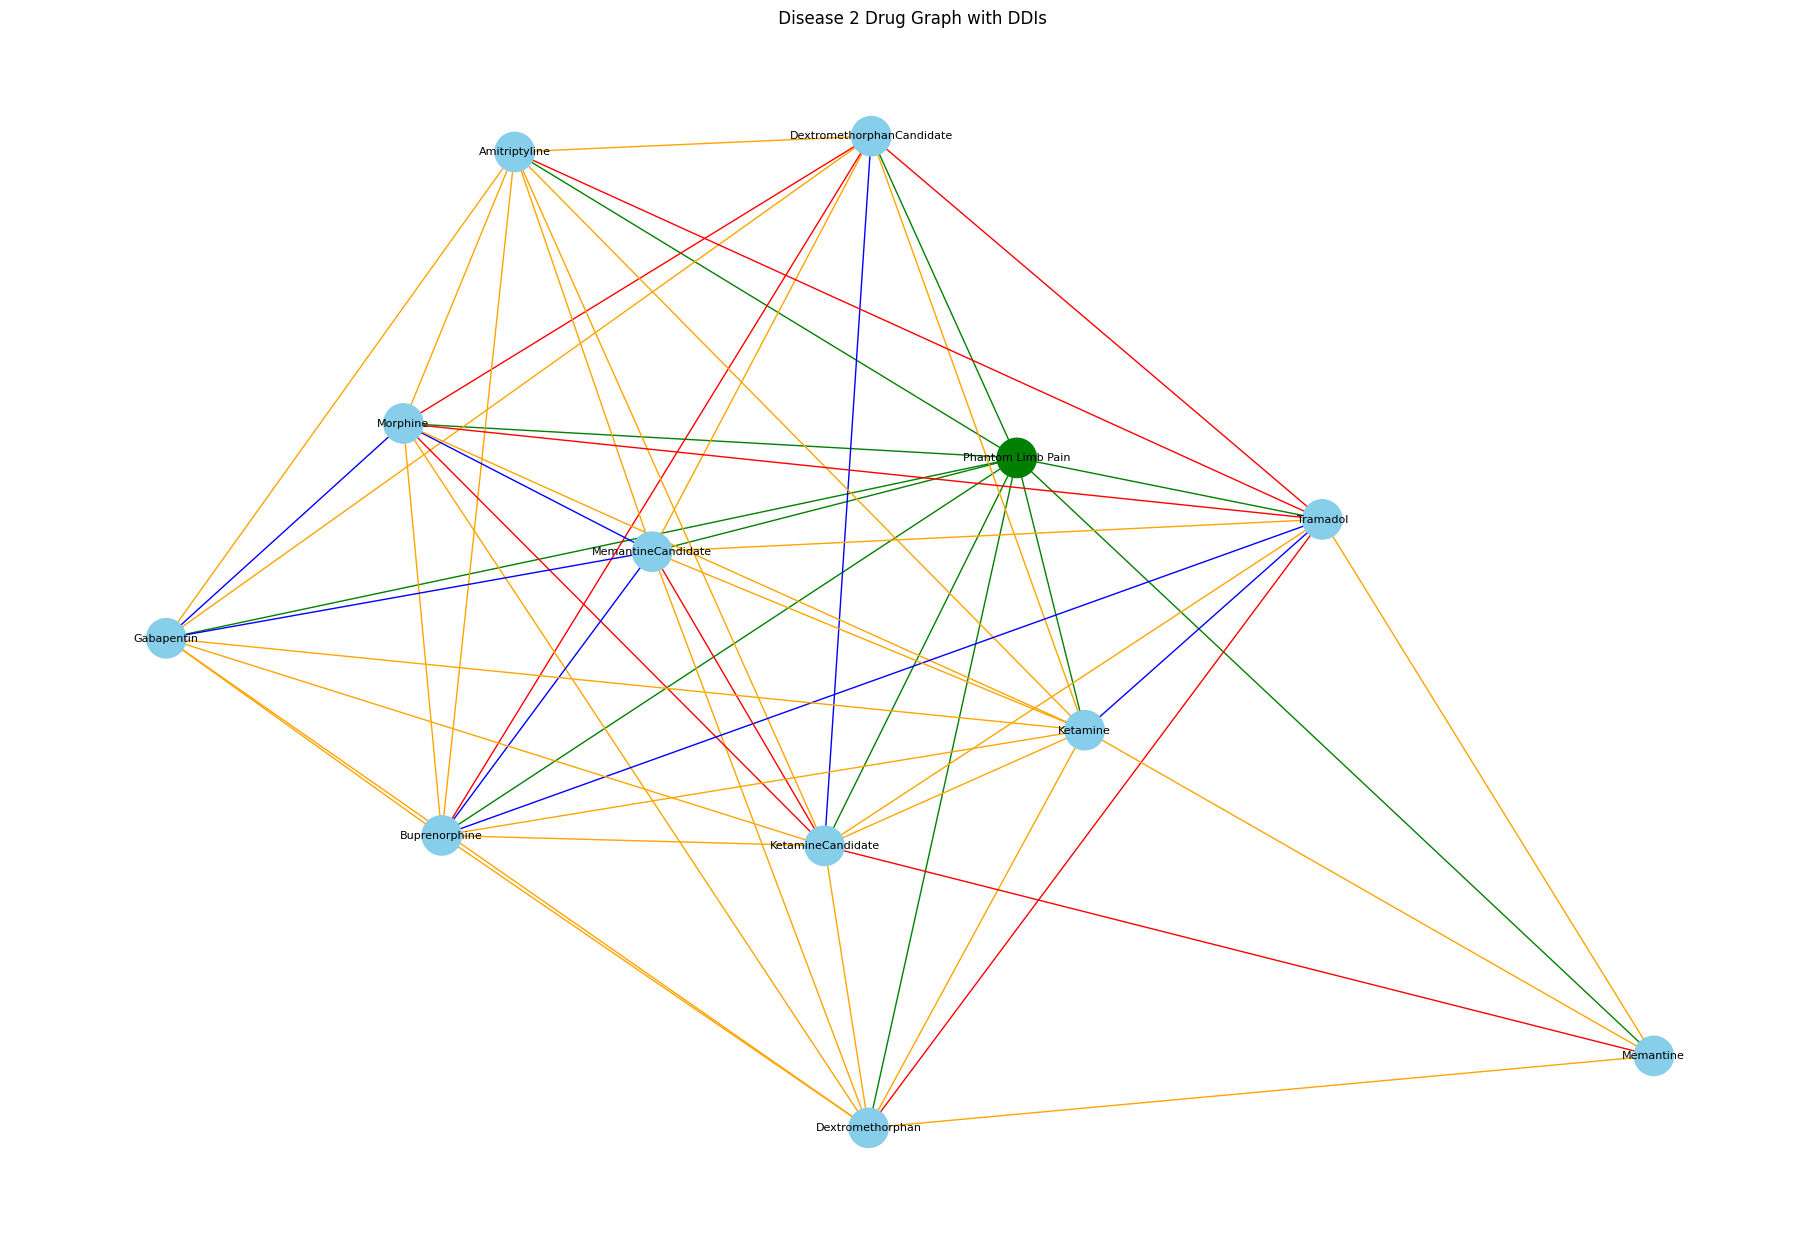

Dropdown(description='Disease1 Drug:', options=('Baclofen', 'Butriptyline', 'Caffeine', 'Cannabidiol', 'Carbam…

Button(description='Show Disease2 Combinations', style=ButtonStyle())

Output()

In [2]:
# Install Required Packages (Colab-compatible)
!pip install -q torch torchvision torchaudio torch-geometric ipywidgets networkx matplotlib scikit-learn
!pip install -q seaborn

# Import Libraries
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report
import networkx as nx
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from itertools import combinations
from collections import Counter
from sklearn.metrics import confusion_matrix
import seaborn as sns


# Upload Your Data
from google.colab import files
uploaded = files.upload()

#  Load Datasets
# Disease 1
disease1_nodes = pd.read_csv("disease1_nodes.csv")
disease1_drugs = pd.read_csv("disease1_drug_nodes.csv")
disease1_edges = pd.read_csv("disease1_edges.csv", encoding="ISO-8859-1")
disease1_mechanism = pd.read_csv("disease1_mechanism_of_action - target.csv", encoding="ISO-8859-1")

# Disease 2
disease2_nodes = pd.read_csv("disease2_nodes.csv")
disease2_drugs = pd.read_csv("disease2_drug_nodes.csv")
disease2_edges = pd.read_csv("disease2_edges.csv", encoding="ISO-8859-1")
disease2_mechanism = pd.read_csv("disease2_mechanism_of_action - target.csv", encoding="ISO-8859-1")


from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Build drug → targets dictionary (Disease 1)
def parse_targets(t):
    if pd.isna(t):
        return set()
    return set(x.strip().lower() for x in str(t).split('/'))

drug_to_targets = {}
for _, row in disease1_mechanism.iterrows():
    drug = row['Drug'].strip().lower()
    targets = parse_targets(row['Target'])
    drug_to_targets[drug] = targets


#  DDI
ddi_df = pd.read_csv("ddi_edges.csv", encoding="ISO-8859-1")
ddi_df['Drug1'] = ddi_df['Drug1'].str.strip()
ddi_df['Drug2'] = ddi_df['Drug2'].str.strip()
ddi_df['Drug1_norm'] = ddi_df['Drug1'].str.lower()
ddi_df['Drug2_norm'] = ddi_df['Drug2'].str.lower()

# Clean DDI severity labels
severity_map = {'mild': 0, 'moderate': 1, 'severe': 2}
ddi_df = ddi_df[ddi_df['Severity'].str.lower().isin(severity_map)]
ddi_df['label'] = ddi_df['Severity'].str.lower().map(severity_map)

# Combine drug vocab
ddi_drugs = pd.unique(ddi_df[['Drug1', 'Drug2']].values.ravel())
d1_drugs = disease1_drugs['Drug'].dropna().unique()
d2_drugs = disease2_drugs['Drug'].dropna().unique()
all_drugs = pd.unique(pd.Series(list(ddi_drugs) + list(d1_drugs) + list(d2_drugs))).astype(str)

# Encode drugs
le = LabelEncoder()
le.fit(all_drugs)
drug_to_idx = {name: idx for idx, name in enumerate(le.classes_)}
idx_to_drug = {v: k for k, v in drug_to_idx.items()}
n_drugs = len(drug_to_idx)
from sklearn.feature_extraction.text import TfidfVectorizer

drug_texts = []

for drug in le.classes_:

    moa = ""

    row1 = disease1_mechanism[
        disease1_mechanism["Drug"].str.lower()==drug.lower()
    ]

    row2 = disease2_mechanism[
        disease2_mechanism["Drug"].str.lower()==drug.lower()
    ]

    if not row1.empty:
        moa += str(row1.iloc[0]["Mechanism"])

    if not row2.empty:
        moa += " " + str(row2.iloc[0]["Mechanism"])

    drug_texts.append(moa)

vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,3),
    min_df=2,
    sublinear_tf=True
)
X_features = vectorizer.fit_transform(drug_texts)

x = torch.tensor(
    X_features.toarray(),
    dtype=torch.float
)

# Build training graph from known DDIs
ddi_df['pair'] = ddi_df[['Drug1', 'Drug2']].apply(lambda row: tuple(sorted(row)), axis=1)
train_ddi_df, temp_df = train_test_split(
    ddi_df,
    test_size=0.2,
    stratify=ddi_df['label'],
    random_state=42
)

val_ddi_df, heldout_ddi_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['label'],
    random_state=42
)
edge_index = torch.tensor(
    [[drug_to_idx[r['Drug1']], drug_to_idx[r['Drug2']]]
     for _, r in train_ddi_df.iterrows()],
    dtype=torch.long
).t()

edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)

edge_labels = torch.tensor(
    train_ddi_df['label'].values,
    dtype=torch.long
)

edge_labels = torch.cat([edge_labels, edge_labels])

test_labels = torch.tensor(
    heldout_ddi_df['label'].values,
    dtype=torch.long
)
edge_index = torch.tensor([[drug_to_idx[r['Drug1']], drug_to_idx[r['Drug2']]] for _, r in train_ddi_df.iterrows()], dtype=torch.long).t()
edge_labels = torch.tensor(train_ddi_df['label'].values, dtype=torch.long)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(edge_labels.numpy()),
    y=edge_labels.numpy()
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float
)

loss_fn = nn.CrossEntropyLoss(weight=class_weights)

data = Data(x=x, edge_index=edge_index, edge_label=edge_labels)

# Define GNN Model
class GNNLinkClassifier(nn.Module):
    def __init__(self, in_channels, hidden_channels, num_classes):
        super().__init__()
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, hidden_channels)
        self.conv3 = SAGEConv(hidden_channels, hidden_channels)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_channels * 2, hidden_channels),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_channels, hidden_channels // 2),
            nn.ReLU(),
            nn.Linear(hidden_channels // 2, num_classes)
        )

    def forward(self, x, edge_index, edge_pairs):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.2, training=self.training)

        x = F.relu(self.conv2(x, edge_index))
        x = F.dropout(x, p=0.2, training=self.training)

        x = self.conv3(x, edge_index)
        edge_feats = torch.cat([x[edge_pairs[0]], x[edge_pairs[1]]], dim=1)
        return self.classifier(edge_feats)

# Train the model
model = GNNLinkClassifier(
    in_channels=x.shape[1],
    hidden_channels=512,
    num_classes=3
).to("cpu")
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0005,
    weight_decay=5e-4)
model.train()

best_loss = float('inf')
patience = 100
counter = 0

for epoch in range(1, 501):

    optimizer.zero_grad()

    out = model(
        data.x,
        data.edge_index,
        data.edge_index
    )

    loss = loss_fn(
        out,
        data.edge_label
    )

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
    optimizer.step()

    if loss.item() < best_loss:

        best_loss = loss.item()
        counter = 0

        torch.save(
            model.state_dict(),
            "best_model.pt"
        )

    else:
        counter += 1

    if counter >= patience:
        print(f"Early stopping at epoch {epoch}")
        break

    if epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | Loss: {loss.item():.4f}"
        )

model.load_state_dict(
    torch.load("best_model.pt")
)

test_edge_index = torch.tensor(
    [
        [drug_to_idx[r['Drug1']], drug_to_idx[r['Drug2']]]
        for _, r in heldout_ddi_df.iterrows()
    ],
    dtype=torch.long
).t()

model.eval()

with torch.no_grad():

    test_logits = model(
        data.x,
        data.edge_index,
        test_edge_index
    )

    test_preds = test_logits.argmax(dim=1)

y_true = test_labels.numpy()
y_pred = test_preds.numpy()

accuracy = accuracy_score(y_true, y_pred)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average='weighted'
)

print("\n========================")
print("MODEL EVALUATION")
print("========================")

print(f"Accuracy: {accuracy:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")

print("\nClassification Report:\n")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            "Mild",
            "Moderate",
            "Severe"
        ]
    )
)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=['Mild','Moderate','Severe'],
    yticklabels=['Mild','Moderate','Severe']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# ============================================================
# Generate cross-disease drug pairs
# Exclude self-interactions only
# ============================================================

# Make sure the drug lists are clean and unique
d1_unique_drugs = sorted(
    set(
        str(d).strip()
        for d in d1_drugs
        if pd.notna(d) and str(d).strip()
    )
)

d2_unique_drugs = sorted(
    set(
        str(d).strip()
        for d in d2_drugs
        if pd.notna(d) and str(d).strip()
    )
)

# Generate Disease 1 × Disease 2 pairs
# ONLY exclude a drug paired with itself.
cross_pairs = [
    (d1, d2)
    for d1 in d1_unique_drugs
    for d2 in d2_unique_drugs
    if d1.lower() != d2.lower()
]

print(f"Total cross-disease pairs: {len(cross_pairs)}")
print("Self-interactions excluded.")


# Convert to graph indices
cross_index = torch.tensor(
    [
        [drug_to_idx[d1], drug_to_idx[d2]]
        for d1, d2 in cross_pairs
        if d1 in drug_to_idx and d2 in drug_to_idx
    ],
    dtype=torch.long
).t()
model.eval()
with torch.no_grad():
    pred_logits = model(data.x, data.edge_index, cross_index)
    pred_classes = pred_logits.argmax(dim=1).tolist()
predicted_cross_ddis = [(d1, d2, ['mild','moderate','severe'][c]) for (d1,d2), c in zip(cross_pairs, pred_classes)]

# Build Full Graphs for Each Disease (Disease 1 and Disease 2)
def build_disease_graph(drug_nodes, edge_data, mechanism_df, disease_name, subtype_col, node_df):
    G = nx.Graph()
    disease_drugs = set(drug_nodes['Drug'].dropna().str.strip())

    # Filter subtypes to only those present in edge data for this disease
    relevant_subtypes = set(edge_data[subtype_col].dropna().str.strip())

    # Add subtype and group nodes if available
    if 'grouped diseaese1 subtypes ' in node_df.columns and subtype_col == 'Disease1_Subtype':
        for _, row in node_df.iterrows():
            subtype = row['Disease1_Subtype'].strip()
            group = row['grouped disease1 subtypes '].strip()
            if subtype in relevant_subtypes:
                G.add_node(group, type='group', color='coral')
                G.add_node(subtype, type='subtype', color='green')
                G.add_edge(group, subtype, type='subtype-of', color='gray')
    else:
        for subtype in relevant_subtypes:
            G.add_node(subtype, type='subtype', color='green')

    # Add drug nodes
    for drug in disease_drugs:
        G.add_node(drug, type='drug', color='skyblue')

    # Add prescription edges
    for _, row in edge_data.iterrows():
        drug = row['Drug'].strip()
        subtype = row[subtype_col].strip()
        if drug in disease_drugs and subtype in relevant_subtypes:
            prescribed = str(row['Prescribed']).strip().lower() == 'yes'
            color = 'green' if prescribed else 'red'
            label = 'prescribed' if prescribed else 'not_prescribed'
            G.add_edge(drug, subtype, type=label, color=color)

    # Add mechanisms
    for _, row in mechanism_df.iterrows():
        drug = row['Drug'].strip()
        if drug in G.nodes:
            G.nodes[drug]['mechanism'] = row['Mechanism']

    # Only include DDIs between drugs of this disease
    for _, row in ddi_df.iterrows():
        d1, d2 = row['Drug1'].strip(), row['Drug2'].strip()
        if d1 in disease_drugs and d2 in disease_drugs:
            sev = row['label']
            color = ['blue', 'orange', 'red'][sev]
            G.add_edge(d1, d2, color=color, type='ddi', severity=sev)

    return G

def draw_graph(G, title):
    pos = nx.spring_layout(G, seed=42)
    node_colors = [G.nodes[n].get('color', 'gray') for n in G.nodes()]
    edge_colors = [G[u][v].get('color', 'gray') for u,v in G.edges()]
    plt.figure(figsize=(18, 12))
    nx.draw(G, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors, node_size=800, font_size=8)
    plt.title(title)
    plt.axis('off')
    plt.show()

# Show Full Graphs
G_disease1 = build_disease_graph(disease1_drugs, disease1_edges, disease1_mechanism, "Disease 1", "Disease1_Subtype", disease1_nodes)
draw_graph(G_disease1, " Disease 1 Drug Graph with DDIs and Subtypes")

G_disease2 = build_disease_graph(disease2_drugs, disease2_edges, disease2_mechanism, "Disease 2", "Disease2_Subtype", disease2_nodes)
draw_graph(G_disease2, " Disease 2 Drug Graph with DDIs")


#  Interactive Recommendation System (with MoA + final graph)
options = sorted(list(d1_drugs))
dropdown = widgets.Dropdown(options=options, description='Disease1 Drug:')
button = widgets.Button(description="Show Disease2 Combinations")
output = widgets.Output()

combined_ddis = set()
for _, row in ddi_df.iterrows():
    d1, d2 = row['Drug1'].strip(), row['Drug2'].strip()
    combined_ddis.add((d1, d2, row['label'], row.get('Interaction', 'Known DDI')))
for d1, d2, label in predicted_cross_ddis:
    combined_ddis.add((d1, d2, severity_map.get(label, 1), 'Predicted DDI'))


def common_targets(drug_a, drug_b):
    t1 = drug_to_targets.get(drug_a.lower(), set())
    t2 = drug_to_targets.get(drug_b.lower(), set())
    return t1.intersection(t2)

#Get all Disease 2 subtypes for a drug
def get_disease2_subtypes(drug_name):
    rows = disease2_edges[
        disease2_edges['Drug'].astype(str).str.strip().str.lower()
        == drug_name.strip().lower()
    ]

    if rows.empty:
        return [("Subtype not available", "Status not available")]

    results = []

    for _, row in rows.iterrows():
        subtype = str(row.get('Disease2_Subtype', 'Unknown')).strip()
        prescribed = str(row.get('Prescribed', 'Unknown')).strip()

        if subtype.lower() in ('nan', 'none', ''):
            subtype = "Subtype not available"

        if prescribed.lower() in ('nan', 'none', ''):
            prescribed = "Status not available"

        item = (subtype, prescribed)

        if item not in results:
            results.append(item)

    return results



@output.capture()
def on_button_click(b):
    drug1 = dropdown.value
    print(f"\n Recommendations for: {drug1}")

    # Find mechanism of input drug
    moa1 = disease1_mechanism[disease1_mechanism['Drug'].str.strip() == drug1].get('Mechanism', ['N/A']).values
    moa1 = moa1[0] if len(moa1) > 0 else 'N/A'
    print(f"Mechanism of Action for {drug1}: {moa1}")

    interactions = []

    for d2 in d2_drugs:
        d1, d2 = drug1.strip(), d2.strip()

        # ========================================================
        # EXCLUDE SELF-INTERACTION
        # ========================================================
        if d1.lower() == d2.lower():
            continue

        match = [
            (a, b, sev, note)
            for a, b, sev, note in combined_ddis
            if {a.lower(), b.lower()} == {d1.lower(), d2.lower()}
        ]

        if match:
            a, b, sev, note = match[0]

            shared = common_targets(d1, d2)

            if shared:
                sev = 2
                note = (
                    f"Risky combination due to shared target(s): "
                    f"{', '.join(shared)}"
                )

            moa2 = disease2_mechanism[
                disease2_mechanism['Drug'].str.strip().str.lower() == d2.lower()
            ].get('Mechanism', ['N/A']).values


            moa2 = moa2[0] if len(moa2) > 0 else 'N/A'

            subtypes2 = get_disease2_subtypes(d2)

            interactions.append((d2, sev, note, moa2, subtypes2))



    if not interactions:
        print(" No interactions found with disease2 drugs.")
        return




    def print_drug_details(drug, note, moa, subtypes):
        print(f"- Disease 2 drug: {drug}")

        print("  Prescribed disease subtype(s):")
        for subtype, status in subtypes:
            print(f"    - {subtype} | Prescribed: {status}")

        print(f"  Interaction: {note}")
        print(f"  Mechanism of Action: {moa}")


    print("\n Safe combinations:")
    safe = [
        (d, n, m, st)
        for d, s, n, m, st in interactions
        if s == 0
    ]

    if safe:
        for d, note, moa, subtypes in safe:
            print_drug_details(d, note, moa, subtypes)
    else:
        print("- None")


    print("\n Risky combinations:")
    risky = [
        (d, s, n, m, st)
        for d, s, n, m, st in interactions
        if s > 0
    ]

    if risky:
        for d, severity, note, moa, subtypes in risky:
            print(
                f"\n- Severity: "
                f"{['mild', 'moderate', 'severe'][severity]}"
            )
            print_drug_details(d, note, moa, subtypes)
    else:
        print("- None")


    # Final Graph
    G = nx.Graph()
    G.add_node(drug1, color='lightgreen')
    subtype_row = disease1_edges[disease1_edges['Drug'].str.strip() == drug1]
    subtype = subtype_row['Disease1_Subtype'].values[0] if not subtype_row.empty else None
    if subtype:
        G.add_node(subtype, color='green')
        G.add_edge(drug1, subtype, color='gray')

    for d, s, note, _, subtypes2 in interactions:
        G.add_node(d, color='skyblue')

        # Connect the Disease 2 drug to ALL its associated subtypes
        for subtype2, prescribed in subtypes2:
            if subtype2 != "Subtype not available":
                G.add_node(subtype2, color='green')
                G.add_edge(d, subtype2, color='gray')

        severity_label = ['mild', 'moderate', 'severe'][s]
        G.add_edge(
            drug1, d,
            color=['blue', 'orange', 'red'][s],
            label=severity_label
        )

    pos = nx.spring_layout(G, seed=42)
    edge_colors = [G[u][v]['color'] for u,v in G.edges()]
    edge_labels = {(u, v): G[u][v]['label'] for u, v in G.edges() if 'label' in G[u][v]}
    node_colors = [G.nodes[n]['color'] for n in G.nodes()]

    plt.figure(figsize=(12, 8))
    nx.draw(G, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors, node_size=1000, font_size=9)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)
    plt.title(f"{drug1} vs Disease2 Drugs with Subtypes & Interaction Severity")
    plt.axis('off')
    plt.show();

button.on_click(on_button_click)
display(dropdown, button, output)
